# Taller 11: Máquinas de Soporte Vectorial

Inteligencia Artificial - ELP 8012 - Universidad del Norte  
Programa de Ingeniería de Sistemas  
Profesor: Eduardo Zurek, Ph.D.  
Grupo 15: Galvis Pajaro, Carlos; Molina Vega, Dayana; Romero Pemberthy, Juan

Este taller pide una máquina de soporte vectorial que clasifique los dígitos del dataset digits de sklearn. Hay que probar distintos kernels, medir el desempeño promedio con validación cruzada k-fold y comparar el resultado con los talleres 9 y 10.


## 1. Cómo dejamos el experimento

Una SVM busca una frontera que separe bien las clases y deje el mayor margen posible entre ellas. Cuando esa frontera no puede ser una línea recta en el espacio de los 64 píxeles, el kernel cambia la forma en que se miden las similitudes entre ejemplos.

Probamos cuatro kernels: linear, poly, rbf y sigmoid. Todos van dentro de un Pipeline con StandardScaler, porque la SVM es sensible a la escala de los atributos. El escalador se ajusta solo con los datos de entrenamiento de cada fold, así no se cuela información de validación ni de prueba.

Usamos la misma semilla 42 de los talleres anteriores. El dataset se parte 80 por ciento para entrenar y 20 por ciento para probar. Sobre el entrenamiento aplicamos StratifiedKFold con 4 folds. La regla de elección, escrita antes de mirar la prueba, es quedarse con el kernel de mayor F1 macro media en esa validación cruzada. Si hay empate, preferimos mayor exactitud media y menor brecha entre entrenamiento y validación. La prueba no se abre hasta tener un ganador.


## 2. Los datos

digits trae 1797 imágenes de 8 por 8 píxeles, con intensidades de 0 a 16. La etiqueta es el dígito, de 0 a 9. Abajo se ven el tamaño de cada partición y un ejemplo de entrenamiento por clase. La prueba no se dibuja.


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import pandas as pd
    HAS_PANDAS = True
except Exception as exc:
    pd = None
    HAS_PANDAS = False
    print("pandas no disponible en este entorno:", type(exc).__name__, "-", exc)
    print("Seguimos con numpy y sklearn; en Colab pandas si carga.")

from sklearn import __version__ as sklearn_version
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from IPython.display import display, Markdown

SEED = 42
N_SPLITS = 4
METRICAS = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
AZUL = "#205C90"
OCRE = "#B46918"
VERDE = "#2E7D4F"
GRIS = "#6B7280"

print("Versiones:", f"NumPy {np.__version__} | scikit-learn {sklearn_version}")
if HAS_PANDAS:
    print("pandas", pd.__version__)
print("Python", sys.version.split()[0])

digits = load_digits()
X, y = digits.data, digits.target
CLASES = digits.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Imagenes: {X.shape[0]} | pixeles: {X.shape[1]} | clases: {len(CLASES)}")
print(f"Intensidad minima: {X.min():.1f} | maxima: {X.max():.1f}")
print(f"Entrenamiento: {X_train.shape[0]} ({100 * X_train.shape[0] / X.shape[0]:.1f}%)")
print(f"Prueba:        {X_test.shape[0]} ({100 * X_test.shape[0] / X.shape[0]:.1f}%)")

conteo = {
    "Clase": list(CLASES),
    "Train": np.bincount(y_train).tolist(),
    "Test": np.bincount(y_test).tolist(),
}
if HAS_PANDAS:
    display(pd.DataFrame(conteo))
else:
    for c, tr, te in zip(conteo["Clase"], conteo["Train"], conteo["Test"]):
        print(f"clase {c}: train={tr}, test={te}")


pandas no disponible en este entorno: ModuleNotFoundError - No module named 'pandas'
Seguimos con numpy y sklearn; en Colab pandas si carga.


Versiones: NumPy 2.5.4 | scikit-learn 1.9.1
Python 3.14.7
Imagenes: 1797 | pixeles: 64 | clases: 10
Intensidad minima: 0.0 | maxima: 16.0
Entrenamiento: 1437 (80.0%)
Prueba:        360 (20.0%)
clase 0: train=142, test=36
clase 1: train=146, test=36
clase 2: train=142, test=35
clase 3: train=146, test=37
clase 4: train=145, test=36
clase 5: train=145, test=37
clase 6: train=145, test=36
clase 7: train=143, test=36
clase 8: train=139, test=35
clase 9: train=144, test=36


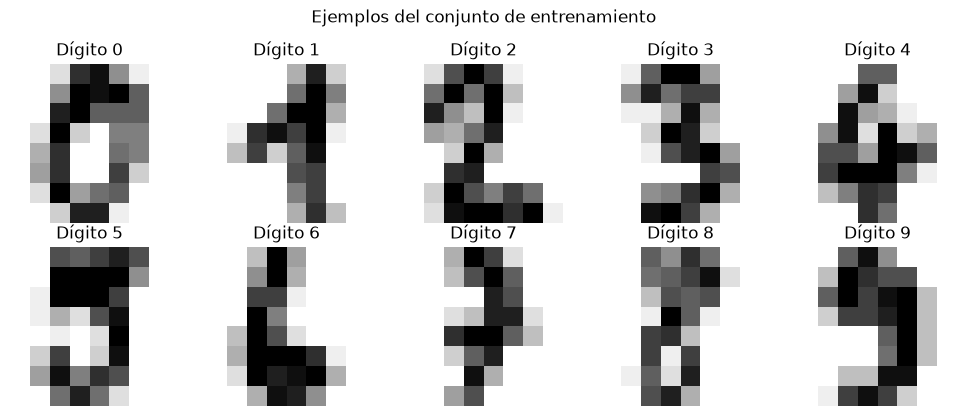

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for digito, ax in enumerate(axes.ravel()):
    idx = np.flatnonzero(y_train == digito)[0]
    ax.imshow(X_train[idx].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Dígito {digito}")
    ax.axis("off")
fig.suptitle("Ejemplos del conjunto de entrenamiento")
fig.tight_layout()
plt.show()


## 3. Validación cruzada

Para estimar el desempeño promedio pedimos cuatro folds estratificados sobre el 80 por ciento de entrenamiento. En cada fold medimos accuracy, precisión macro, recall macro y F1 macro. Así comparamos kernels con la misma partición y sin tocar la prueba.


In [3]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))

print(f"Número de folds: {len(folds)}")
for i, (tr, va) in enumerate(folds, start=1):
    print(f"  Fold {i}: train={len(tr)}, val={len(va)}")


Número de folds: 4
  Fold 1: train=1077, val=360
  Fold 2: train=1078, val=359
  Fold 3: train=1078, val=359
  Fold 4: train=1078, val=359


## 4. Comparación de kernels

Construimos cuatro SVMs iguales en todo menos el kernel. Dejamos C en 1.0, que es el valor por defecto de scikit-learn. Para poly usamos grado 3, también el default. Guardamos el promedio y la desviación de cada indicador en validación, más la brecha entre F1 de entrenamiento y F1 de validación.


Kernel | Acc_val | F1_val | Brecha_F1
rbf      | 0.9812 | 0.9811 | 0.0164
linear   | 0.9756 | 0.9754 | 0.0246
poly     | 0.9457 | 0.9482 | 0.0270
sigmoid  | 0.9436 | 0.9432 | 0.0142

Mejor por F1 macro en CV: rbf (F1_val=0.9811)


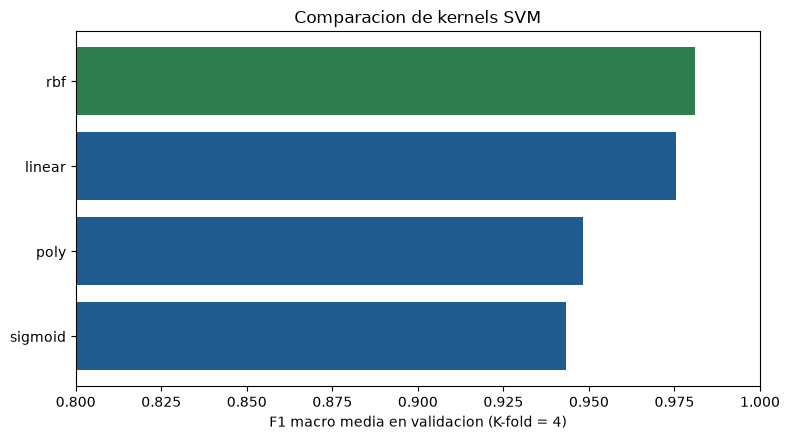

In [4]:
def hacer_svm(kernel):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel=kernel, C=1.0, random_state=SEED)),
    ])


def evaluar_cv(modelo, X, y, cv):
    scores = cross_validate(
        modelo,
        X,
        y,
        cv=cv,
        scoring=METRICAS,
        return_train_score=True,
        n_jobs=-1,
    )
    return {
        "Acc_val": scores["test_accuracy"].mean(),
        "Acc_val_std": scores["test_accuracy"].std(),
        "Prec_val": scores["test_precision_macro"].mean(),
        "Rec_val": scores["test_recall_macro"].mean(),
        "F1_val": scores["test_f1_macro"].mean(),
        "F1_val_std": scores["test_f1_macro"].std(),
        "F1_train": scores["train_f1_macro"].mean(),
        "Brecha_F1": scores["train_f1_macro"].mean() - scores["test_f1_macro"].mean(),
    }


KERNELS = ["linear", "poly", "rbf", "sigmoid"]
filas = []
for kernel in KERNELS:
    fila = {"Kernel": kernel}
    fila.update(evaluar_cv(hacer_svm(kernel), X_train, y_train, cv))
    filas.append(fila)

filas = sorted(filas, key=lambda r: r["F1_val"], reverse=True)
if HAS_PANDAS:
    tabla_cv = pd.DataFrame(filas)
    display(tabla_cv.round(4))
else:
    tabla_cv = filas
    print("Kernel | Acc_val | F1_val | Brecha_F1")
    for f in filas:
        print(f"{f['Kernel']:8s} | {f['Acc_val']:.4f} | {f['F1_val']:.4f} | {f['Brecha_F1']:.4f}")

mejor_kernel = filas[0]["Kernel"]
mejor_f1 = float(filas[0]["F1_val"])
print(f"\nMejor por F1 macro en CV: {mejor_kernel} (F1_val={mejor_f1:.4f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
orden = [f["Kernel"] for f in sorted(filas, key=lambda r: r["F1_val"])]
vals = [next(f["F1_val"] for f in filas if f["Kernel"] == k) for k in orden]
colores = [VERDE if k == mejor_kernel else AZUL for k in orden]
ax.barh(orden, vals, color=colores)
ax.set_xlabel("F1 macro media en validacion (K-fold = 4)")
ax.set_title("Comparacion de kernels SVM")
ax.set_xlim(0.8, 1.0)
fig.tight_layout()
plt.show()


## 5. Lectura de los resultados y elección del kernel

El ranking sale de la tabla anterior. En dígitos de 8 por 8, un kernel radial suele adaptarse mejor que uno lineal porque algunos pares de dígitos se parecen y no se separan con una frontera plana. El polinomial puede acercarse. El sigmoid suele quedar más atrás.

La celda siguiente deja fijado el ganador según la regla de la sección 1 y reentrena ese modelo con todo el entrenamiento.


In [5]:
print("Ranking por F1_val:")
for i, row in enumerate(filas):
    print(
        f"  {i + 1}. {row['Kernel']}: "
        f"F1={row['F1_val']:.4f} ± {row['F1_val_std']:.4f}, "
        f"Acc={row['Acc_val']:.4f}, brecha={row['Brecha_F1']:.4f}"
    )

modelo_final = hacer_svm(mejor_kernel)
modelo_final.fit(X_train, y_train)

print(f"\nKernel elegido: {mejor_kernel}")
print(f"F1 macro CV: {mejor_f1:.4f}")


Ranking por F1_val:
  1. rbf: F1=0.9811 ± 0.0094, Acc=0.9812, brecha=0.0164
  2. linear: F1=0.9754 ± 0.0077, Acc=0.9756, brecha=0.0246
  3. poly: F1=0.9482 ± 0.0053, Acc=0.9457, brecha=0.0270
  4. sigmoid: F1=0.9432 ± 0.0025, Acc=0.9436, brecha=0.0142



Kernel elegido: rbf
F1 macro CV: 0.9811


## 6. Evaluación en la prueba

Recién ahora usamos el 20 por ciento reservado. Reportamos accuracy, precisión macro, recall macro, F1 macro, el classification report y la matriz de confusión.


kernel: rbf
accuracy: 0.975
precision_macro: 0.976
recall_macro: 0.9748
f1_macro: 0.9748
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9459    0.9722    0.9589        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     0.9459    0.9722    0.9589        36
           5     0.9737    1.0000    0.9867        37
           6     0.9730    1.0000    0.9863        36
           7     0.9211    0.9722    0.9459        36
           8     1.0000    0.9143    0.9552        35
           9     1.0000    0.9167    0.9565        36

    accuracy                         0.9750       360
   macro avg     0.9760    0.9748    0.9748       360
weighted avg     0.9759    0.9750    0.9749       360



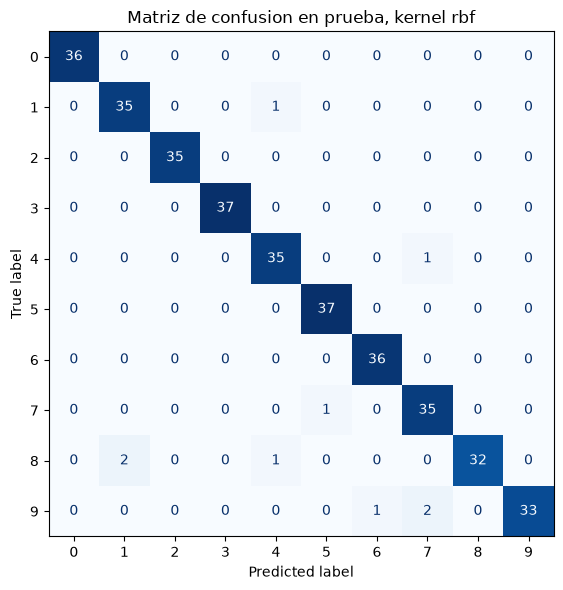

Total de errores: 9 de 360


In [6]:
y_pred = modelo_final.predict(X_test)

metricas_test = {
    "kernel": mejor_kernel,
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro"),
    "recall_macro": recall_score(y_test, y_pred, average="macro"),
    "f1_macro": f1_score(y_test, y_pred, average="macro"),
}
if HAS_PANDAS:
    display(pd.DataFrame([metricas_test]).round(4))
else:
    for k, v in metricas_test.items():
        print(f"{k}: {v if not isinstance(v, float) else round(v, 4)}")

print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=CLASES,
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusion en prueba, kernel {mejor_kernel}")
fig.tight_layout()
plt.show()

errores = np.flatnonzero(y_pred != y_test)
print(f"Total de errores: {len(errores)} de {len(y_test)}")


## 7. Comparación con los talleres 9 y 10

Los tres trabajos usan digits y semilla 42. Los números de los talleres 9 y 10 salen de sus cuadernos resueltos.

En el taller 9 el modelo final fue MultinomialNB con alpha 1 y llegó a accuracy 0.8889 en la prueba. En el taller 10 el ganador fue una MLP con activación relu y accuracy 0.9639 en la prueba. Aquí el SVM usa el kernel elegido arriba. Vale notar que el taller 10 partió 60, 20 y 20 en lugar de usar k-fold, pero la prueba también tiene 360 imágenes, así que el hold-out sirve para comparar el desempeño final.


{'Taller': 9, 'Modelo': 'MultinomialNB (alpha=1)', 'Accuracy_test': 0.8889, 'F1_macro_test': 0.8871, 'Fuente': 'taller09, prueba 20%'}
{'Taller': 10, 'Modelo': 'MLP (relu, 30 hidden)', 'Accuracy_test': 0.9639, 'F1_macro_test': 0.9639, 'Fuente': 'taller10, prueba 20%'}
{'Taller': 11, 'Modelo': 'SVM (rbf)', 'Accuracy_test': 0.975, 'F1_macro_test': 0.9748467821381158, 'Fuente': 'este cuaderno, prueba 20%'}


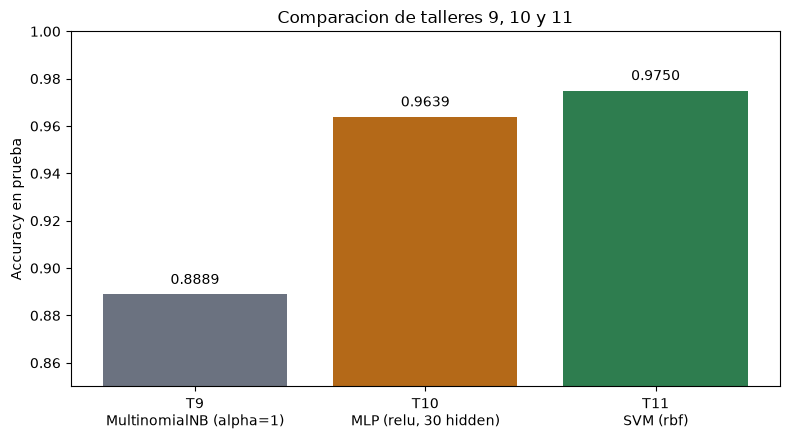

Lectura rapida.

El taller 9 quedo cerca de 0.8889. Es el mas simple y el que mas se queda corto, porque asume independencia entre pixeles.

El taller 10 llego a 0.9639 con la red relu. Esa arquitectura captura patrones no lineales del trazo.

Este taller, con SVM y kernel rbf, llega a 0.9750. Queda claramente por encima del bayesiano y en el mismo orden de magnitud que la red.

In [7]:
filas_comp = [
    {
        "Taller": 9,
        "Modelo": "MultinomialNB (alpha=1)",
        "Accuracy_test": 0.8889,
        "F1_macro_test": 0.8871,
        "Fuente": "taller09, prueba 20%",
    },
    {
        "Taller": 10,
        "Modelo": "MLP (relu, 30 hidden)",
        "Accuracy_test": 0.9639,
        "F1_macro_test": 0.9639,
        "Fuente": "taller10, prueba 20%",
    },
    {
        "Taller": 11,
        "Modelo": f"SVM ({mejor_kernel})",
        "Accuracy_test": metricas_test["accuracy"],
        "F1_macro_test": metricas_test["f1_macro"],
        "Fuente": "este cuaderno, prueba 20%",
    },
]

if HAS_PANDAS:
    comparacion = pd.DataFrame(filas_comp)
    display(comparacion.round(4))
else:
    for r in filas_comp:
        print(r)

fig, ax = plt.subplots(figsize=(8, 4.5))
etiquetas = [f"T{r['Taller']}\n{r['Modelo']}" for r in filas_comp]
vals_acc = [r["Accuracy_test"] for r in filas_comp]
barras = ax.bar(etiquetas, vals_acc, color=[GRIS, OCRE, VERDE])
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Accuracy en prueba")
ax.set_title("Comparacion de talleres 9, 10 y 11")
for barra, valor in zip(barras, vals_acc):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.003,
        f"{valor:.4f}",
        ha="center",
        va="bottom",
    )
fig.tight_layout()
plt.show()

acc_t9, acc_t10, acc_t11 = 0.8889, 0.9639, metricas_test["accuracy"]
display(Markdown(
    f"""Lectura rapida.

El taller 9 quedo cerca de {acc_t9:.4f}. Es el mas simple y el que mas se queda corto, porque asume independencia entre pixeles.

El taller 10 llego a {acc_t10:.4f} con la red relu. Esa arquitectura captura patrones no lineales del trazo.

Este taller, con SVM y kernel {mejor_kernel}, llega a {acc_t11:.4f}. Queda claramente por encima del bayesiano y en el mismo orden de magnitud que la red."""
))


## 8. Cierre

Nos quedamos con el kernel que ganó la validación cruzada de cuatro folds.

La SVM supera al Naive Bayes del taller 9 porque no fuerza independencia entre píxeles y puede dibujar fronteras no lineales. Frente a la MLP del taller 10 queda en un rango competitivo: ambos se mueven por encima de 0.96 cuando el kernel radial gana, y los dos dejan atrás al clasificador bayesiano.

El escalado dentro del Pipeline forma parte del diseño. Sin él, los kernels basados en distancia, sobre todo rbf, se degradan. La semilla fija hace que la comparación de kernels se pueda repetir. El tiempo de entrenamiento puede variar un poco entre corridas, pero el ranking no debería cambiar si las versiones de las librerías se mantienen.


In [8]:
assert X_train.shape[0] == 1437 and X_test.shape[0] == 360
assert len(folds) == 4
assert mejor_kernel in KERNELS
assert isinstance(modelo_final.named_steps["svc"], SVC)
assert modelo_final.named_steps["svc"].kernel == mejor_kernel
assert metricas_test["accuracy"] > 0.8889
print(f"Checks del taller OK: 80/20, K-fold=4, SVM kernel={mejor_kernel}.")


Checks del taller OK: 80/20, K-fold=4, SVM kernel=rbf.


## Referencias

La documentación de SVC y de las máquinas de soporte vectorial de scikit-learn:

https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

https://scikit-learn.org/stable/modules/svm.html

El dataset digits:

https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

Los resultados de comparación salen de los cuadernos resueltos del taller 9 y del taller 10.
